实验二——最终感染密度关于移动概率p在不同α取值情况下的图像

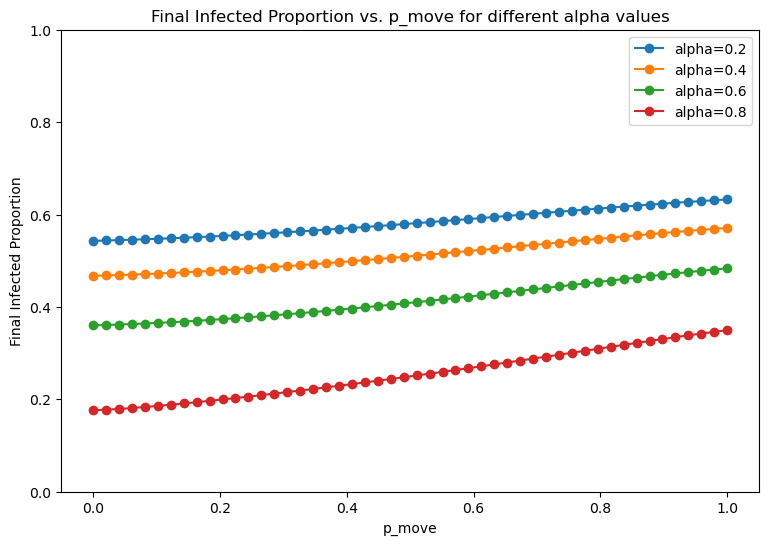

In [7]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random
import pandas as pd

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

# 生成小世界网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
def generate_small_world_network(N, k, p_rewire):
    G = nx.watts_strogatz_graph(N, k, p_rewire)
    for u, v in G.edges():
        G[u][v]['weight'] = random.randint(1, 10)
    W = nx.to_numpy_array(G, weight='weight')
    return W

# 计算C矩阵
def calculate_C_matrix(W):
    N = W.shape[0]
    C = np.zeros_like(W, dtype=float)
    for i in range(N):
        row_sum = np.sum(W[i, :])
        if row_sum > 0:
            C[i, :] = W[i, :] / row_sum
    return C

# 生成每个子种群的网络并计算平均度
def generate_subpopulations(N):
    n = np.full(N, 100)
    average_degrees = n * 0.3
    return n, average_degrees

# 运行模拟实验
def run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps):
    rho = np.full(N, initial_infected_density)
    for t in range(steps):
        new_rho = np.zeros(N)
        R_i = np.zeros(N)
        D_i = np.zeros(N)
        P_i = np.zeros(N)
        Pi_i = np.zeros(N)
        for i in range(N):
            R_i[i] = 1 - (1 - beta) ** ((1 - p_move) * average_degrees[i] * rho[i] +
                                     np.sum([p_move * C[j, i] * average_degrees[j] * rho[j] for j in range(N)]))
            D_i[i] = 1 - (1 - beta) ** ((1 - p_move) * n[i] * rho[i] * 0.9  +
                                     np.sum([p_move * C[j, i] * n[j] * rho[j] for j in range(N)]))
            P_i[i] = alpha * R_i[i] + (1 - alpha) * D_i[i]
        for i in range(N):
            Pi_i[i] = (1 - p_move) * P_i[i] + p_move * np.sum([C[i, j] * P_i[j] for j in range(N)])
            new_rho[i] = (1 - mu) * rho[i] + (1 - rho[i]) * Pi_i[i]
        rho = new_rho
    return np.mean(rho)

# 初始变量
N = 50
k = 5
p_rewire = 0.8
initial_infected_density = 0.01

mu = 0.1
beta = 0.003  # 固定 beta 值
steps = 200

# 生成小世界网络
W = generate_small_world_network(N, k, p_rewire)

# 计算C矩阵
C = calculate_C_matrix(W)

# 生成每个子种群的网络并计算平均度
n, average_degrees = generate_subpopulations(N)

# 不同的移动概率值 p_move
p_move_values = np.linspace(0, 1, 50)  # 生成从0到1之间的10个p_move值

# 不同的 alpha 值
alpha_values = [0.2,0.4,0.6, 0.8]  # 可以根据需要调整 alpha 的取值

# 记录不同 alpha 值下的结果
all_results = {}

for alpha in alpha_values:
    results = []
    for p_move in p_move_values:
        simulation_results = []
        for _ in range(3):  # 平均运行3次
            result = run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps)
            simulation_results.append(result)
        average_result = np.mean(simulation_results)
        results.append(average_result)

    all_results[alpha] = results

# 绘制结果
plt.figure(figsize=(9, 6))
for alpha, results in all_results.items():
    plt.plot(p_move_values, results, marker='o', label=f'alpha={alpha}')
plt.xlabel('p_move')
plt.ylabel('Final Infected Proportion')
plt.ylim(0, 1)  # 设置y轴范围
plt.title('Final Infected Proportion vs. p_move for different alpha values')
plt.legend()
plt.show()


W matrix:
[[ 0.  9.  4. 10.  0.]
 [ 9.  0.  0.  0.  1.]
 [ 4.  0.  0.  0.  9.]
 [10.  0.  0.  0.  0.]
 [ 0.  1.  9.  0.  0.]]
C matrix:
[[0.         0.39130435 0.17391304 0.43478261 0.        ]
 [0.9        0.         0.         0.         0.1       ]
 [0.30769231 0.         0.         0.         0.69230769]
 [1.         0.         0.         0.         0.        ]
 [0.         0.1        0.9        0.         0.        ]]
p_move=0.0, alpha=0.2, simulation_results=[0.5428796458847418, 0.5428796458847418, 0.5428796458847418, 0.5428796458847418]
p_move=0.1111111111111111, alpha=0.2, simulation_results=[0.5487221107881128, 0.5487221107881128, 0.5487221107881128, 0.5487221107881128]
p_move=0.2222222222222222, alpha=0.2, simulation_results=[0.5585447667251395, 0.5585447667251395, 0.5585447667251395, 0.5585447667251395]
p_move=0.3333333333333333, alpha=0.2, simulation_results=[0.5716972007093141, 0.5716972007093141, 0.5716972007093141, 0.5716972007093141]
p_move=0.4444444444444444, alpha=0.2

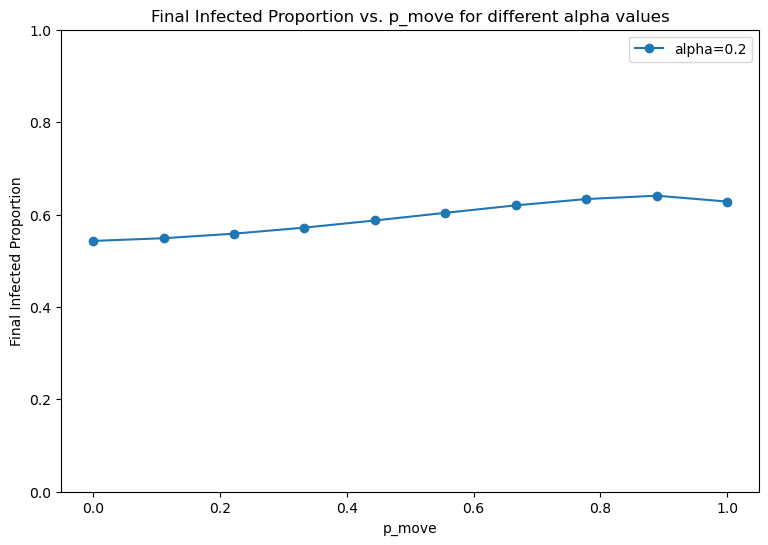

In [18]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import random
import pandas as pd

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

# 生成小世界网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
def generate_small_world_network(N, k, p_rewire):
    G = nx.watts_strogatz_graph(N, k, p_rewire)
    for u, v in G.edges():
        G[u][v]['weight'] = random.randint(1, 10)
    W = nx.to_numpy_array(G, weight='weight')
    return W

# 计算C矩阵
def calculate_C_matrix(W):
    N = W.shape[0]
    C = np.zeros_like(W, dtype=float)
    for i in range(N):
        row_sum = np.sum(W[i, :])
        if row_sum > 0:
            C[i, :] = W[i, :] / row_sum
    return C

# 生成每个子种群的网络并计算平均度
def generate_subpopulations(N):
    n = np.full(N, 100)
    average_degrees = n * 0.3
    return n, average_degrees

# 运行模拟实验
def run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps):
    rho = np.full(N, initial_infected_density)
    for t in range(steps):
        new_rho = np.zeros(N)
        R_i = np.zeros(N)
        D_i = np.zeros(N)
        P_i = np.zeros(N)
        Pi_i = np.zeros(N)
        for i in range(N):
            R_i[i] = 1 - (1 - beta) ** ((1 - p_move) * average_degrees[i] * rho[i] +
                                     np.sum([p_move * C[j, i] * average_degrees[j] * rho[j] for j in range(N)]))
            D_i[i] = 1 - (1 - beta) ** ((1 - p_move) * n[i] * rho[i] * 0.9  +
                                     np.sum([p_move * C[j, i] * n[j] * rho[j] for j in range(N)]))
            P_i[i] = alpha * R_i[i] + (1 - alpha) * D_i[i]
        for i in range(N):
            Pi_i[i] = (1 - p_move) * P_i[i] + p_move * np.sum([C[i, j] * P_i[j] for j in range(N)])
            new_rho[i] = (1 - mu) * rho[i] + (1 - rho[i]) * Pi_i[i]
        rho = new_rho
    return np.mean(rho)

# 初始变量
N = 5
k = 2
p_rewire = 0.8
initial_infected_density = 0.01

mu = 0.1
beta = 0.003  # 固定 beta 值
steps = 100

# 生成小世界网络
W = generate_small_world_network(N, k, p_rewire)
print(f'W matrix:\n{W}')

# 计算C矩阵
C = calculate_C_matrix(W)
print(f'C matrix:\n{C}')

# 生成每个子种群的网络并计算平均度
n, average_degrees = generate_subpopulations(N)

# 不同的移动概率值 p_move
p_move_values = np.linspace(0, 1, 10)  # 生成从0到1之间的10个p_move值

# 不同的 alpha 值
alpha_values = [0.2]  # 可以根据需要调整 alpha 的取值

# 记录不同 alpha 值下的结果
all_results = {}

for alpha in alpha_values:
    results = []
    for p_move in p_move_values:
        simulation_results = []

        for _ in range(3):  # 平均运行3次
            result = run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps)
            simulation_results.append(result)
        average_result = np.mean(simulation_results)
        # print(f'p_move={p_move}, alpha={alpha}, simulation_results={simulation_results}')
        # print(f'p_move={p_move}, alpha={alpha}, average_result={average_result}')

        results.append(average_result)
        # print(results)
        # print('\n')

    all_results[alpha] = results

# 绘制结果
plt.figure(figsize=(9, 6))
for alpha, results in all_results.items():
    plt.plot(p_move_values, results, marker='o', label=f'alpha={alpha}')
plt.xlabel('p_move')
plt.ylabel('Final Infected Proportion')
plt.ylim(0, 1)  # 设置y轴范围
plt.title('Final Infected Proportion vs. p_move for different alpha values')
plt.legend()
plt.show()


In [17]:
import numpy as np
alpha_values = np.arange(0.0, 1.1, 0.1)  # 生成从0到1之间的α值
mu_values = np.linspace(0.5, 0.1, 10)   # 生成从0.1到0.5之间的μ值

print(alpha_values)
print(mu_values)

len(alpha_values) #11
len(alpha_values) // 2 #5
len(alpha_values) - 1    #10


beta_values = np.concatenate([  # 感染率 beta 的取值区间
    np.arange(0.0003, 0.001, 0.0003),
    np.arange(0.001, 0.003, 0.0001),
    np.arange(0.003, 0.004, 0.0002),
    np.arange(0.004, 0.01, 0.001),
    np.arange(0.01, 0.02, 0.002),
    np.arange(0.02, 0.1, 0.01),
    np.arange(0.1, 0.3, 0.05)
])  #51


beta_values = np.arange(0.001, 0.101, 0.001) 
len(beta_values)

[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
[0.5        0.45555556 0.41111111 0.36666667 0.32222222 0.27777778
 0.23333333 0.18888889 0.14444444 0.1       ]


100